In [49]:
# package import
import numpy as np
from numpy import arange
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error


In [15]:
# loading data
X_train_data = pd.read_csv("X_train_processed_61.csv")
y_train_data = pd.read_csv("y_train.csv")

X_train = X_train_data.values
y_train = y_train_data.values.ravel()

In [16]:
import json

In [17]:
with open("column_names.json", "w") as f:
    json.dump(list(X_train_data.columns), f, indent=2)

In [18]:
# starting model:
# healthcare_system_confidence, -government_covid_response, -i11_health
# -perceived_covid_severity, -age, -avoiding_infected_people
# -hand_sanitizer_frequency
# -i12_health_13, -i12_health_22, -i12_health_25

starting_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
    "ord__hand_sanitizer_frequency",
    "ord__i12_health_13",
    "ord__i12_health_22",
    "ord__i12_health_25",
]

In [19]:
# expanded model
# starting model + perceived_infection_risk + employment_status

expanded_cols = starting_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]

In [20]:
# compact model
# starting model - last four variables

compact_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
]

In [21]:
X_train_starting = X_train_data[starting_cols].values
X_train_expanded = X_train_data[expanded_cols].values
X_train_compact = X_train_data[compact_cols].values

In [22]:
feature_sets = {
    "all_61": X_train,
    "starting_model": X_train_starting,
    "expanded_model": X_train_expanded,
    "compact_model": X_train_compact,
}

In [65]:
num_folds = 10
seed = 42
scoring = 'neg_mean_squared_error'
model = KNeighborsClassifier()
kfold = StratifiedKFold(n_splits=num_folds, random_state=seed, shuffle=True)



In [66]:
# check for each model

k_values = [3, 5, 7, 9, 11, 21, 25]
param_grid = dict(n_neighbors=k_values)
all_cv_mse = {}
all_stds = {}
all_params = {}

for name, X_sub in feature_sets.items():
    # scale this model's columns
    scaler = StandardScaler().fit(X_sub)
    rescaledX = scaler.transform(X_sub)

    # try every k with 10-fold CV
    grid = GridSearchCV(estimator=model, param_grid=param_grid,
                        scoring=scoring, cv=kfold)
    grid_result = grid.fit(rescaledX, y_train)

    print("=== %s ===" % name)
    print("Best: %f using K = %s" % ((-1)*grid_result.best_score_, int(grid_result.best_params_['n_neighbors'])))

    cv_mse = (-1)*grid_result.cv_results_['mean_test_score']
    cv_stds = grid_result.cv_results_['std_test_score']
    cv_params = grid_result.cv_results_['params']

    all_cv_mse[name] = cv_mse 
    all_stds[name] = cv_stds
    all_params[name] = cv_params


=== all_61 ===
Best: 0.230950 using K = 9
=== starting_model ===
Best: 0.222971 using K = 25
=== expanded_model ===
Best: 0.224724 using K = 21
=== compact_model ===
Best: 0.220052 using K = 21


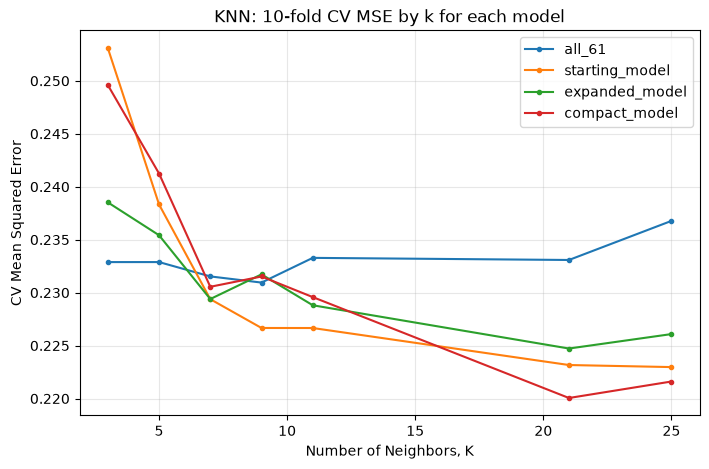

In [67]:
# plot K vs cv_mse

plt.figure(figsize=(8, 5))
for name, cv_mse in all_cv_mse.items():
    plt.plot(k_values, cv_mse, marker='o', markersize=3, label=name)

plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Mean Squared Error")
plt.title("KNN: 10-fold CV MSE by k for each model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [68]:
bal_scoring = 'balanced_accuracy'

all_cv_balacc = {}
all_stds = {}

for name, X_sub in feature_sets.items():
    scaler = StandardScaler().fit(X_sub)
    rescaledX = scaler.transform(X_sub)

    grid = GridSearchCV(estimator=model, param_grid=param_grid,
                        scoring=bal_scoring, cv=kfold)
    grid_result = grid.fit(rescaledX, y_train)

    print("=== %s ===" % name)
    print("Best balanced accuracy: %f using K = %d" %
          (grid_result.best_score_, grid_result.best_params_['n_neighbors']))

    all_cv_balacc[name] = grid_result.cv_results_['mean_test_score']
    all_stds[name]      = grid_result.cv_results_['std_test_score']

=== all_61 ===
Best balanced accuracy: 0.675828 using K = 3
=== starting_model ===
Best balanced accuracy: 0.681378 using K = 7
=== expanded_model ===
Best balanced accuracy: 0.680317 using K = 3
=== compact_model ===
Best balanced accuracy: 0.678931 using K = 7


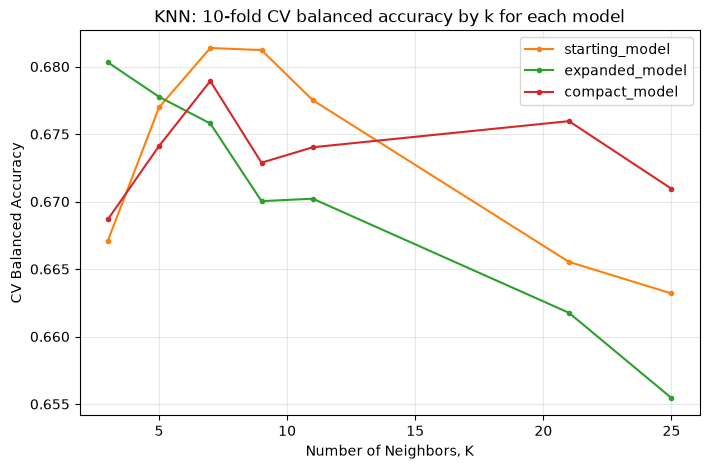

In [73]:
colors = {"all_61": "C0", "starting_model": "C1",
          "expanded_model": "C2", "compact_model": "C3"}

plt.figure(figsize=(8, 5))
for name, score in all_cv_balacc.items():
    if name == "all_61":
        continue   
    plt.plot(k_values, score, marker='o', markersize=3, label=name, color=colors[name])
plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Balanced Accuracy")
plt.title("KNN: 10-fold CV balanced accuracy by k for each model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()